In [ ]:
# Handwritten Digit Recognition using Support Vector Machine (SVM)

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay



In [ ]:
# 1. Load the dataset
digits = load_digits()
X = digits.data
y = digits.target

# 2. Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [ ]:
# 3. Scale the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Create and train the SVM classifier
model = SVC(kernel="rbf", C=10, gamma="scale")
model.fit(X_train, y_train)

# 5. Predict the digits
y_pred = model.predict(X_test)



Accuracy: 98.06 %

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      0.97      0.97        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.95      0.97      0.96        36
           5       0.97      1.00      0.99        37
           6       0.97      1.00      0.99        36
           7       0.95      0.97      0.96        36
           8       1.00      0.94      0.97        35
           9       1.00      0.94      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



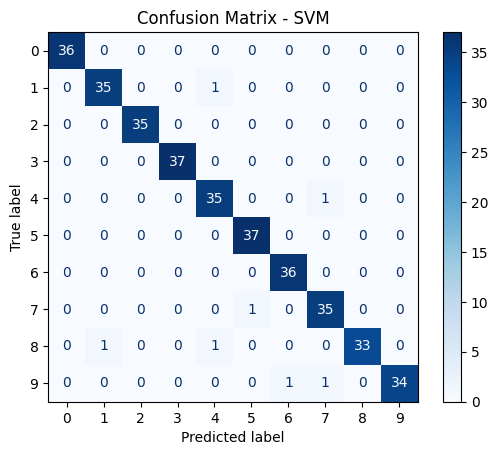

In [ ]:
# 6. Evaluate the model
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

# 7. Display the confusion matrix
cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=digits.target_names
)
display.plot(cmap="Blues")
plt.title("Confusion Matrix - SVM")
plt.show()



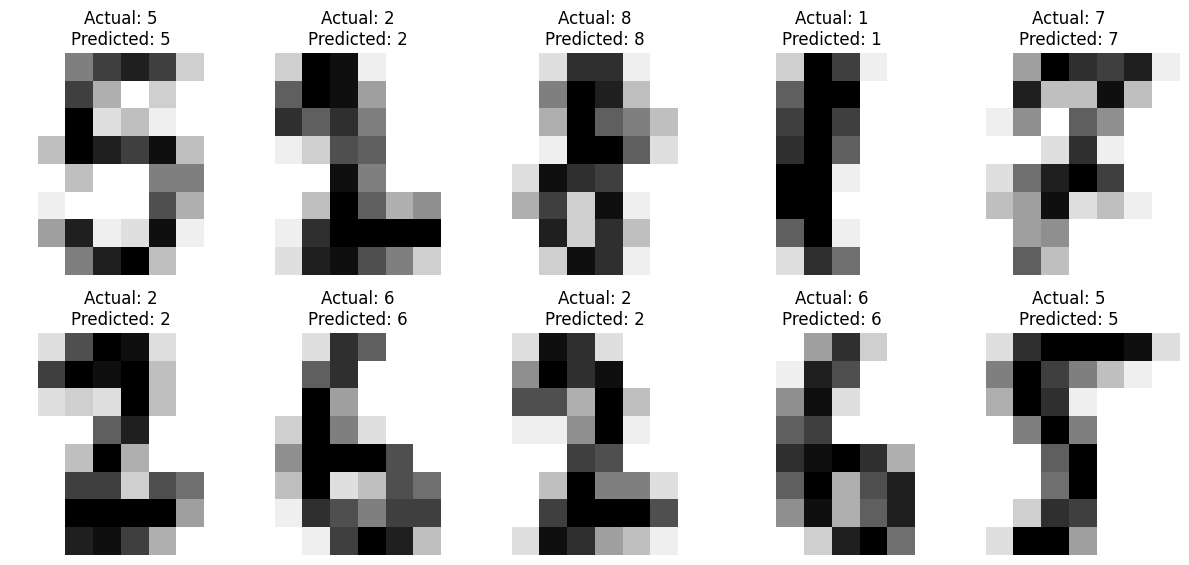

In [ ]:
# 8. Display sample test images with actual and predicted labels

_, test_indices = train_test_split(
    np.arange(len(digits.target)),
    test_size=0.2,
    random_state=42,
    stratify=digits.target
)

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        digits.images[test_indices[i]],
        cmap="gray_r",
        interpolation="nearest"
    )
    ax.set_title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()
